# Replication of the experiments of Chapter 3

**Thesis:** Luca Palmacci, PhD in Models for Economics and Finance (XXXIX cycle), Sapienza University of Rome.
**Chapter 3:** the Confidex model, the reconstructed law of the members' probabilities, and the reliability signal.
**Library:** `confidex` 0.5.1, the Python implementation of the procedure (Chapter 3, *Implementation*); its
numerical results are identical to those of version 0.5.0, with which the thesis was computed.

This notebook recomputes every number and every figure of Chapter 3 from fixed random seeds, and checks each
recomputed value against the reference files `results/chapter3_results.json` and `results/auroc_gap_bootstrap.json`,
written by `run_experiments.py`, which hold the values reported in the thesis. The script `check_values.py` then
checks every number printed in the chapter against those files.
It is meant for a reader who wants to verify the results, not only to look at them, so every experiment is
preceded by a statement of what it measures, how, and where in the chapter it is used.

**How to read it.**

1. Section 0 sets up the environment and the checks.
2. Section 1 restates the model and the procedure in the notation of the chapter, and verifies the numerical
   core of the library against independent computations.
3. Sections 2–6 reproduce the experiments in the order in which the chapter uses them.
4. Section 7 reports, for every recomputed quantity, whether it matches the reference.

**Running time.** About 15–20 minutes on a laptop with `RECOMPUTE = True`, dominated by the synthetic validation
and its bootstrap (Section 4) and by the inferred-mean comparison (Section 5). With `RECOMPUTE = False` the notebook reads the
reference values and only draws the figures, in under a minute.

**Thesis cross-references.** Sections, equations and remarks of the thesis are cited by their LaTeX labels,
for instance `sec:conf-validation` or `eq:conf-pred`. The table at the end of Section 0 lists every label used here
with the element of the chapter it denotes.

## 0. Environment and reproducibility

The computations are deterministic. Each experimental condition draws its own random numbers from a generator
seeded with a key that depends only on the condition (design, threshold, number of members, purpose), so a
condition gives the same numbers whether it is run alone or as part of the whole notebook, and in any order.
The seeding scheme is the one of `run_experiments.py` (function `seed_for` of `synthetic.py`): each component of the key is mapped to an integer
(`int(1000 * x)` for a threshold, the integer itself for a number of members, the sum of the character codes for
a string), and the resulting list seeds `numpy.random.default_rng`.

The results were produced with the package versions printed below. With the same versions they are reproduced
exactly; with different versions of NumPy or SciPy the last digits may change, and the checks of Section 7
then report the size of the difference.

In [1]:
import json
import platform
import time
from pathlib import Path

import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import gridspec
from scipy.integrate import quad
from scipy.special import betaln, expit, logit
from scipy.stats import beta as B, spearmanr

import confidex as cx
from confidex import ModelConfig

from synthetic import DESIGNS, simulate, auroc, baselines   # synthetic generator and comparison readings
import style                                                # figure style of the thesis

print(f"Python      {platform.python_version()}")
print(f"NumPy       {np.__version__}")
print(f"SciPy       {scipy.__version__}")
print(f"Matplotlib  {matplotlib.__version__}")
print(f"confidex    {cx.__version__}")
assert cx.__version__ in ("0.5.0", "0.5.1"), "Chapter 3 was computed with confidex 0.5"

Python      3.12.11
NumPy       2.5.3
SciPy       1.18.1
Matplotlib  3.11.2
confidex    0.5.1


In [2]:
# ---- options ----------------------------------------------------------------------------------
RECOMPUTE = True          # False: read the reference values and only draw the figures
SAVE_FIGURES = False      # True: also write the figures, as PDF, into ./figures (make_figures.py writes them anyway)
REFERENCE = Path("results/chapter3_results.json")
FIGDIR = Path("figures"); FIGDIR.mkdir(exist_ok=True)

REF = json.loads(REFERENCE.read_text())


def seed_for(*keys):
    # Seed of one experimental condition (identical to seed_for in synthetic.py).
    return np.random.default_rng([int(1000 * k) if isinstance(k, float)
                                  else (k if isinstance(k, int) else sum(map(ord, k))) for k in keys])


# ---- checks against the reference ------------------------------------------------------------
CHECKS = []          # (section, quantity, recomputed, reference, absolute difference)

def check(section, name, value, reference, tol=1e-9):
    # Record a recomputed value against its reference; tol is an absolute tolerance.
    # Arrays are compared element by element, so that every value counts once in the report.
    if isinstance(value, (list, tuple, np.ndarray)):
        value, reference = np.ravel(np.asarray(value, dtype=float)), np.ravel(np.asarray(reference, dtype=float))
        assert value.shape == reference.shape, f"{name}: shape differs from the reference"
        return all([check(section, f"{name}[{i}]", v, r, tol) for i, (v, r) in enumerate(zip(value, reference))])
    diff = abs(float(value) - float(reference))
    CHECKS.append((section, name, diff, diff <= tol))
    return diff <= tol

def report(section):
    rows = [c for c in CHECKS if c[0] == section]
    ok = sum(c[3] for c in rows)
    worst = max((c[2] for c in rows), default=0.0)
    print(f"[{section}] {ok}/{len(rows)} recomputed values match the reference (largest difference {worst:.1e})")
    for c in rows:
        if not c[3]:
            print(f"    MISMATCH  {c[1]}: difference {c[2]:.3e}")


# ---- figure style -----------------------------------------------------------------------------
# The thesis figures use LaTeX (Computer Modern). style.setup() falls back to Matplotlib's own mathtext,
# with the same layout, when latex, dvipng or the cm-super fonts are not available.
USETEX = style.setup()
print("LaTeX rendering of figures:", "on" if USETEX else "off (latex, dvipng or cm-super not available)")
OI, TEXTWIDTH = style.OI, style.TEXTWIDTH
PCT = r"\%" if USETEX else "%"      # a percent sign must be escaped under LaTeX

def show(fig, name):
    if SAVE_FIGURES:
        fig.savefig(FIGDIR / f"{name}.pdf")
    plt.show()


LaTeX rendering of figures: off (latex, dvipng or cm-super not available)


**Correspondence with the thesis.** Labels of Chapter 3 cited in this notebook.

| Label | Element of Chapter 3 |
|---|---|
| `sec:conf-model`, `fig:coupled-density`, `tab:coupled-moments` | coupled and decoupled models |
| `sec:conf-specs`, `fig:joint-posterior` | three specifications of the decoupled model; joint posterior under independent priors |
| `sec:conf-assumptions`, `hyp:independence`, `hyp:beta`, `hyp:fixed-mean` | assumptions of the fixed-mean specification |
| `sec:conf-inference`, `eq:conf-loglik`, `prop:induced-prior`, `prop:ties` | inference on the concentration, prior, grid, exact ties |
| `sec:conf-relative`, `fig:decoupled-density`, `lem:maxvar`, `rem:inadmissible` | the concentration is a relative measure |
| `sec:conf-law`, `eq:conf-pred`, `eq:conf-sigma`, `prop:cancel`, `eq:conf-law` | the predictive law and its approximation at $\bar c$ |
| `rem:dimensional`, `rem:mom` | the cancellation is dimensional, not numerical; why the posterior and not the moments |
| `sec:conf-signal`, `crit:band`, `eq:conf-u`, `rem:gate` | the reliability signal; the admissibility gate and why it is not used |
| `sec:conf-implementation` | the library |
| `sec:conf-sensitivity` | sensitivity to the modelling choices |
| `sec:conf-illustration`, `fig:illustration` | the illustration on ten ensembles |
| `sec:conf-validation`, `fig:validation`, `fig:amplification`, `fig:budget` | what the signal detects when the truth is known |
| `sec:conf-limits` | what the signal says, and its limits |
| `app:replication` | the ten ensembles and the settings of every experiment (Appendix, Table A.1) |

*Labels taken from the source of Chapter 3 (version of 6 October 2026).*

## 1. The model and the procedure

For one case, an ensemble of $K$ members returns the probabilities $\mathbf P=(p_1,\dots,p_K)$ of the positive class.
The decoupled specification treats them, given the parameters, as independent draws from

$$
p_k \mid \mu, c \;\sim\; \mathrm{Beta}\bigl(\mu\lambda,\,(1-\mu)\lambda\bigr),
\qquad \lambda=\lambda_0\,\frac{c}{1-c},\qquad k=1,\dots,K,
$$

where $\mu$ is the location and $c\in(0,1)$ the concentration; $c=1/2$ corresponds to $\lambda=\lambda_0$, and the
default anchoring is $\lambda_0=K$. Under the fixed-mean specification used throughout the chapter, $\mu$ is set to
the mean of the members, $\bar p$, after clipping the probabilities to $[10^{-6},1-10^{-6}]$. The only unknown is then
$c$, with prior $c\sim\mathrm{Beta}(2,3)$, and with $a=\bar p\lambda$, $b=(1-\bar p)\lambda$ the log-likelihood is
(`eq:conf-loglik`)

$$
\log L(\mathbf P\mid c)=(a-1)S_1+(b-1)S_2-K\log\mathrm{B}(a,b),\qquad
S_1=\sum_k\log p_k,\quad S_2=\sum_k\log(1-p_k).
$$

The posterior $p(c\mid\mathbf P)$ is computed on a grid of 1000 points equally spaced on the logit scale over
$(10^{-6},1-10^{-6})$, with trapezoidal cell weights $w_j$, giving masses $m_j$ (`sec:conf-inference`).

**Predictive law.** The probability that a further member would assign to the case has distribution function
(`eq:conf-pred`)

$$
F_{\mathrm{pred}}(t)=\sum_{j} m_j\,F_{\mathrm{Beta}}\bigl(t;\,\bar p\lambda_j,\,(1-\bar p)\lambda_j\bigr),
\qquad \sigma_{\mathrm{pred}}^2=\bar p(1-\bar p)\,\mathrm E\!\left[\tfrac{1}{\lambda+1}\,\middle|\,\mathbf P\right],
$$

a mixture of Beta laws with common mean $\bar p$ (`eq:conf-sigma`, `prop:cancel`). Its approximation at the
posterior mean $\bar c$ is the single law $F_{\bar c}$ of `eq:conf-law`.

**Criterion.** The ensemble decides $\hat y=\mathbf 1[\bar p\ge\tau]$. The signed score (`eq:conf-u`) is

$$
u=\begin{cases}\tfrac12-F_{\mathrm{pred}}(\tau)&\hat y=1\\[2pt] F_{\mathrm{pred}}(\tau)-\tfrac12&\hat y=0\end{cases}
\in\bigl[-\tfrac12,\tfrac12\bigr],
$$

negative when the law contradicts the decision. The case is declared confident when $u>\tfrac12-\alpha$, with
$\alpha=0.40$ fixed in advance (`crit:band`). Wherever a reading is ranked as a score of doubt, the score is $-u$.

The defaults below are those of the library, and every computation of the chapter uses them unless stated.

In [3]:
from dataclasses import asdict
print("ModelConfig    ", asdict(cx.DEFAULT_MODEL))
print("CriterionConfig", asdict(cx.DEFAULT_CRITERION))

ModelConfig     {'prior_a': 2.0, 'prior_b': 3.0, 'lambda0': None, 'lambda0_scale': 1.0, 'grid_bound': 1e-06, 'grid_points': 1000, 'clip_eps': 1e-06, 'tie_eps': 1e-09, 'border_fraction': 0.02, 'border_tol': 0.001}
CriterionConfig {'alpha': 0.4, 'abstention': 0.1}


### 1.1 Numerical checks of the library

Before using the library, three of its computations are compared with independent ones.

1. **Posterior mean of $c$ against adaptive quadrature.** For random ensembles of 3, 6 and 12 members, $\mathrm E[c\mid\mathbf P]$
   from the grid is compared with the same integral computed by `scipy.integrate.quad` on the logit scale.
2. **Variance of the predictive law.** $\sigma^2_{\mathrm{pred}}$ returned by the library is compared with the variance of the
   mixture computed directly from the grid masses, $\sum_j m_j\,\bar p(1-\bar p)/(\lambda_j+1)$ (`prop:cancel`).
3. **Predictive law against Monte Carlo.** $F_{\mathrm{pred}}(\tau)$ is compared with the empirical distribution function of
   draws obtained by first drawing $c$ from the grid posterior and then a member from the corresponding Beta law.

The full test suite of the library (18 tests) is run with `pytest tests/` in the library folder.

In [4]:
def synthetic_beta_rng(n, K, rng):
    # Ensembles drawn from the model itself, with random location and concentration.
    mu, c = rng.uniform(0.02, 0.98, n), rng.beta(2, 3, n)
    lam = K * c / (1 - c)
    return np.clip(rng.beta((mu * lam)[:, None], ((1 - mu) * lam)[:, None], (n, K)), 1e-6, 1 - 1e-6)

def synthetic_beta(n, K, seed):
    rng = np.random.default_rng(seed)
    mu, c = rng.uniform(0.02, 0.98, n), rng.beta(2, 3, n)
    lam = K * c / (1 - c)
    return np.clip(rng.beta((mu * lam)[:, None], ((1 - mu) * lam)[:, None], (n, K)), 1e-6, 1 - 1e-6)

def quad_posterior_mean(x, a0=2.0, b0=3.0):
    K, mu = len(x), x.mean(); S1, S2 = np.log(x).sum(), np.log1p(-x).sum()
    def lp(t):                                   # log posterior density of t = logit(c), Jacobian included
        c = expit(t); lam = K * c / (1 - c); a, b = mu * lam, (1 - mu) * lam
        return (a - 1) * S1 + (b - 1) * S2 - K * betaln(a, b) + B.logpdf(c, a0, b0) + np.log(c) + np.log1p(-c)
    lo, hi = logit(1e-6), logit(1 - 1e-6); ts = np.linspace(lo, hi, 4001)
    M = max(lp(t) for t in ts); f = lambda t: np.exp(lp(t) - M)
    Z = quad(f, lo, hi, limit=400, points=ts[::400])[0]
    return quad(lambda t: expit(t) * f(t), lo, hi, limit=400, points=ts[::400])[0] / Z

worst = 0.0
for K in (3, 6, 12):
    X = synthetic_beta(15, K, seed=K)
    post = cx.fit_posterior(X)
    worst = max(worst, max(abs(post.c_mean[i] - quad_posterior_mean(X[i])) for i in range(len(X))))
print(f"1. largest |grid - quadrature| for E[c | P]:        {worst:.1e}")
assert worst < 2e-5

X = synthetic_beta(200, 6, seed=10)
post = cx.fit_posterior(X, keep_masses=True, taus=[0.3])
lam = post.lambda0 * post.grid.g / (1 - post.grid.g)
mix_var = (post.masses * (post.mu[:, None] * (1 - post.mu[:, None]) / (lam[None, :] + 1))).sum(axis=1)
d2 = np.max(np.abs(post.sigma_pred ** 2 - mix_var))
print(f"2. largest |sigma_pred^2 - mixture variance|:       {d2:.1e}")
assert d2 < 1e-12

rng = np.random.default_rng(1); n_mc = 200_000; d3 = 0.0
for i in range(5):
    j = rng.choice(len(lam), size=n_mc, p=post.masses[i])
    draws = rng.beta(post.mu[i] * lam[j], (1 - post.mu[i]) * lam[j])
    d3 = max(d3, abs(np.mean(draws <= 0.3) - post.F_pred[0.3][i]))
print(f"3. largest |F_pred(0.3) - Monte Carlo| (5 cases):   {d3:.1e}   (Monte Carlo s.e. <= {0.5/np.sqrt(n_mc):.1e})")
assert d3 < 5 * 0.5 / np.sqrt(n_mc)

1. largest |grid - quadrature| for E[c | P]:        7.4e-06
2. largest |sigma_pred^2 - mixture variance|:       4.2e-17
3. largest |F_pred(0.3) - Monte Carlo| (5 cases):   6.6e-04   (Monte Carlo s.e. <= 1.1e-03)


## 2. The two parametrisations of the Beta law (`sec:conf-model`, `fig:coupled-density`; `sec:conf-relative`, `fig:decoupled-density`)

The first two figures of the chapter are analytical: they show the densities on which the two specifications rest,
and use no random numbers.

* **Coupled.** The mean of the Beta law is the parameter $c$ itself. With $c=0.9$ and $\lambda\in\{1,10,50\}$ the law
  changes shape completely while keeping its mean, so a single parameter cannot separate where the members are
  from how much they agree.
* **Decoupled.** Location $\mu$ and precision are separate. With the same precision ($\lambda=9$, so that the parameters
  are $9\mu$ and $9(1-\mu)$) the standard deviation $\sqrt{\mu(1-\mu)/(\lambda+1)}$ depends on $\mu$: the same
  concentration means a different dispersion at different locations, which is the point developed in
  `sec:conf-relative`.

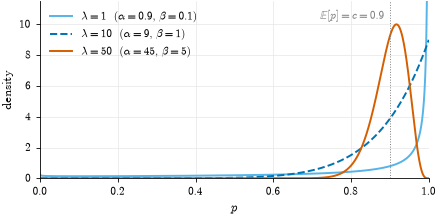

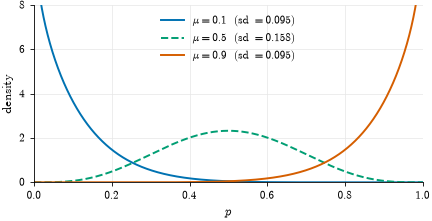

In [5]:
x = np.linspace(1e-4, 1 - 1e-4, 4000)
fig, ax = plt.subplots(figsize=(TEXTWIDTH * 0.85, 2.3))
for lam_, col, ls in ((1, OI["sky"], "-"), (10, OI["blue"], "--"), (50, OI["vermillion"], "-")):
    a, b = 0.9 * lam_, 0.1 * lam_
    ax.plot(x, B.pdf(x, a, b), color=col, ls=ls, label=rf"$\lambda={lam_}$  ($\alpha={a:g}$, $\beta={b:g}$)")
ax.axvline(0.9, color=OI["grey"], lw=0.7, ls=":")
ax.text(0.885, 10.9, r"$\mathbb{E}[p]=c=0.9$", ha="right", va="top", fontsize=8, color=OI["grey"])
ax.set(xlim=(0, 1), ylim=(0, 11.5), xlabel=r"$p$", ylabel="density"); ax.legend(loc="upper left")
show(fig, "confidex_coupled_density")

fig, ax = plt.subplots(figsize=(TEXTWIDTH * 0.85, 2.3))
for mu_, col, ls in ((0.1, OI["blue"], "-"), (0.5, OI["green"], "--"), (0.9, OI["vermillion"], "-")):
    a, b = 9 * mu_, 9 * (1 - mu_); sd = np.sqrt(mu_ * (1 - mu_) / 10)
    ax.plot(x, B.pdf(x, a, b), color=col, ls=ls, label=rf"$\mu={mu_}$  (sd $={sd:.3f}$)")
ax.set(xlim=(0, 1), ylim=(0, 8), xlabel=r"$p$", ylabel="density"); ax.legend(loc="upper center")
show(fig, "confidex_decoupled_density")

## 3. The illustration on ten ensembles (`sec:conf-illustration`, `fig:illustration`)

**What it shows.** How the reading of the concentration and the criterion differ on the same cases. The ten
ensembles of ten members are those of the original presentation of the model (Galiani et al., 2026), listed in
`app:details`. Ensembles 1–5 are tightly concentrated around $0.95$, $0.05$, $0.50$, $0.12$ and $0.88$; ensembles
6–10 are dispersed (spread, split in two groups, polarised).

**What is computed.** For each ensemble, the posterior mean $\bar c$, and the value $F_{\mathrm{pred}}(\tau)$ and the verdict
of the criterion at $\tau=0.5$ and $\tau=0.1$, with both the predictive law and the law at $\bar c$. No random numbers
are involved.

**What to look for.** Ensemble 3, whose members agree on a value next to $\tau=0.5$, receives the highest
concentration, yet is declared not confident at $\tau=0.5$: the concentration ranks first the case closest to a coin
toss. The verdict changes with the threshold while $\bar c$ does not.

In [6]:
TEN = np.array([
    [0.95,0.96,0.94,0.95,0.95,0.96,0.94,0.95,0.96,0.95], [0.05,0.04,0.06,0.05,0.04,0.05,0.06,0.05,0.04,0.05],
    [0.48,0.50,0.49,0.51,0.50,0.52,0.49,0.48,0.51,0.50], [0.12,0.11,0.13,0.12,0.14,0.13,0.12,0.11,0.13,0.12],
    [0.88,0.87,0.89,0.88,0.86,0.89,0.88,0.87,0.89,0.88], [0.1,0.9,0.3,0.7,0.2,0.8,0.4,0.6,0.5,0.9],
    [0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0],           [0.1,0.1,0.1,0.1,0.1,0.9,0.9,0.9,0.9,0.9],
    [0.2,0.8,0.5,0.6,0.4,0.7,0.3,0.9,0.1,0.5],           [0.02,0.99,0.01,0.98,0.03,0.97,0.02,0.96,0.01,0.95]])

post = cx.fit_posterior(TEN, taus=[0.5, 0.1]); law = cx.member_law(post)
ILL = {"cbar": post.c_mean.tolist()}
for tau in (0.5, 0.1):
    o = cx.confidence_score(post, law, tau); op = cx.confidence_score(post, law, tau, predictive=False)
    ILL[f"F_{tau}"], ILL[f"Fplug_{tau}"] = o["F_tau"].tolist(), op["F_tau"].tolist()
    ILL[f"conf_{tau}"], ILL[f"confplug_{tau}"] = o["confident"].tolist(), op["confident"].tolist()
    ILL[f"opposite_{tau}"] = o["opposite_side"].tolist()

for k in ("cbar", "F_0.5", "Fplug_0.5", "F_0.1", "Fplug_0.1"):
    check("illustration", k, ILL[k], REF["illustration"][k], tol=1e-12)
for k in ("conf_0.5", "confplug_0.5", "conf_0.1", "confplug_0.1"):
    check("illustration", k, np.array(ILL[k], float), np.array(REF["illustration"][k], float), tol=0)
report("illustration")

print("\n ens   pbar    cbar   F(0.5)  verdict   F(0.1)  verdict")
for i in range(10):
    v = lambda t: "conf" if ILL[f"conf_{t}"][i] else "NOT"
    print(f"{i+1:4d}  {TEN[i].mean():.3f}  {ILL['cbar'][i]:.3f}  {ILL['F_0.5'][i]:.3f}  {v(0.5):>6}    "
          f"{ILL['F_0.1'][i]:.3f}  {v(0.1):>6}")

[illustration] 90/90 recomputed values match the reference (largest difference 0.0e+00)

 ens   pbar    cbar   F(0.5)  verdict   F(0.1)  verdict
   1  0.951  0.965  0.000    conf    0.000    conf
   2  0.049  0.965  1.000    conf    0.996    conf
   3  0.498  0.976  0.539     NOT    0.000    conf
   4  0.123  0.973  1.000    conf    0.075    conf
   5  0.879  0.971  0.000    conf    0.000    conf
   6  0.540  0.233  0.436     NOT    0.044    conf
   7  0.500  0.017  0.500     NOT    0.417     NOT
   8  0.500  0.131  0.500     NOT    0.148    conf
   9  0.500  0.268  0.500     NOT    0.043    conf
  10  0.494  0.067  0.507     NOT    0.266    conf


**Values quoted in the chapter.** The cell below prints the quantities on which the text of
`sec:conf-illustration` relies, so that each sentence can be checked against them.

In [7]:
cb = np.array(ILL["cbar"])
print(f"cbar of the concentrated ensembles: {cb[:5].min():.3f} to {cb[:5].max():.3f}; highest: ensemble {cb.argmax()+1}")
print(f"F_pred(0.5) for ensemble 3: {ILL['F_0.5'][2]:.3f}  (inside the central band [0.40, 0.60])")
print("confident at tau = 0.5:", [i + 1 for i in range(10) if ILL["conf_0.5"][i]])
print("not confident at tau = 0.1:", [i + 1 for i in range(10) if not ILL["conf_0.1"][i]])
gap = max(max(abs(a - b) for a, b in zip(ILL[f"F_{t}"], ILL[f"Fplug_{t}"])) for t in (0.5, 0.1))
print(f"largest |F_pred(tau) - F_cbar(tau)| over the ten ensembles and both thresholds: {gap:.4f}")
print("verdicts of the two laws identical:", all(ILL[f"conf_{t}"] == ILL[f"confplug_{t}"] for t in (0.5, 0.1)))
print("cases where the law lies on the side opposite to the decision:",
      sum(ILL["opposite_0.5"]) + sum(ILL["opposite_0.1"]))

cbar of the concentrated ensembles: 0.965 to 0.976; highest: ensemble 3
F_pred(0.5) for ensemble 3: 0.539  (inside the central band [0.40, 0.60])
confident at tau = 0.5: [1, 2, 4, 5]
not confident at tau = 0.1: [7]
largest |F_pred(tau) - F_cbar(tau)| over the ten ensembles and both thresholds: 0.0119
verdicts of the two laws identical: True
cases where the law lies on the side opposite to the decision: 0


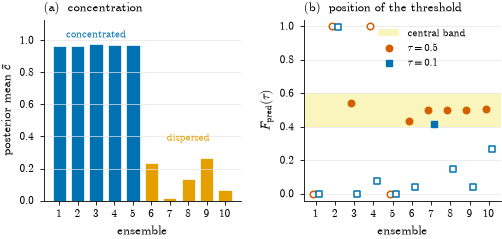

In [8]:
I = ILL; idx = np.arange(1, 11)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(TEXTWIDTH, 2.35), gridspec_kw={"wspace": 0.32})
a1.bar(idx, I["cbar"], color=[OI["blue"]] * 5 + [OI["orange"]] * 5, edgecolor="white", lw=0.5, width=0.72)
a1.set(xticks=idx, ylim=(0, 1.13), yticks=[0, 0.2, 0.4, 0.6, 0.8, 1.0], xlabel="ensemble", ylabel=r"posterior mean $\bar c$")
a1.set_title(r"(a)  concentration", loc="left"); a1.grid(axis="x", visible=False)
a1.text(3, 1.005, "concentrated", ha="center", va="bottom", fontsize=7.5, color=OI["blue"])
a1.text(8, 0.36, "dispersed", ha="center", va="bottom", fontsize=7.5, color=OI["orange"])
a2.axhspan(0.4, 0.6, color=OI["yellow"], alpha=0.35, lw=0, label="central band")
for tau, mk, col, off in ((0.5, "o", OI["vermillion"], -0.16), (0.1, "s", OI["blue"], 0.16)):
    F = np.array(I[f"F_{tau}"]); conf = np.array(I[f"conf_{tau}"])
    a2.scatter(idx[conf] + off, F[conf], marker=mk, s=22, facecolor="white", edgecolor=col, lw=1.1, zorder=3)
    a2.scatter(idx[~conf] + off, F[~conf], marker=mk, s=22, color=col, zorder=3, label=rf"$\tau={tau}$")
a2.set(xticks=idx, ylim=(-0.04, 1.04), xlabel="ensemble", ylabel=r"$F_{\mathrm{pred}}(\tau)$")
a2.set_title(r"(b)  position of the threshold", loc="left"); a2.grid(axis="x", visible=False)
a2.legend(loc="upper center", bbox_to_anchor=(0.6, 1.0), fontsize=7.5)
show(fig, "confidex_illustration")

*Filled markers: not confident. Open markers: confident. Shaded: the central band $[0.40,0.60]$.*

## 4. What the signal detects when the truth is known (`sec:conf-validation`)

### 4.1 Design

The ten ensembles have no truth attached. This experiment supplies one: synthetic cases with a known probability
$q$ of the positive class, on which the correct decision is that of an oracle who knows $q$, $\mathbf 1[q\ge\tau]$.

For each case, $\mathrm{logit}(q)\sim\mathcal N(\mathrm{logit}\,\tau,\,1.5^2)$, so that many cases lie near the threshold, and the
members estimate $q$ with noise on the logit scale:

$$
p_k=\mathrm{expit}\bigl(\mathrm{logit}(q)+b+\eta\,\varepsilon_k\bigr),\qquad \varepsilon_k\sim\mathcal N(0,1)\ \text{i.i.d.},\qquad
\eta\sim\mathcal U[0.05,1.2]\ \text{per case},
$$

where $\eta\varepsilon_k$ is noise of the member, which produces disagreement, and $b$ an error shared by all
members, which the disagreement cannot reveal. The three designs differ in how the error of $\bar p$ relates to the
disagreement:

| Design | Construction | Consequence |
|---|---|---|
| informative | $b=0$ | the error of $\bar p$ comes from the members' noise and grows with their disagreement |
| non-informative | $\varepsilon$ centred within each case; $b\sim\mathcal N(0,\beta^2)$, $\beta\sim\mathcal U[0.05,1.2]$ independent of $\eta$ | the noise produces disagreement without moving the mean logit; the error comes from $b$ alone |
| mixed | $\varepsilon$ not centred; $b\sim\mathcal N(0,0.5^2)$ | both sources |

The members' law is logit-normal, not Beta, so the model holds only approximately. The generator is the function
`simulate` of `synthetic.py`, printed below. Each condition has 20 000 cases, for $K\in\{3,6,12,24,36\}$ and
$\tau\in\{0.5,0.1\}$: thirty conditions in all.

### 4.2 Outcome and scores

A case is an **error** when the decision of the ensemble differs from that of the oracle,
$\mathbf 1[\bar p\ge\tau]\ne\mathbf 1[q\ge\tau]$. Each reading of the probabilities is turned into a score of doubt and
scored by the **AUROC** with which it separates errors from correct decisions: the probability that a randomly
chosen error receives more doubt than a randomly chosen correct decision. The AUROC is computed from mid-ranks
(Mann–Whitney), so that ties count one half, after rounding the scores to ten decimals. The rounding matters:
with many members the signal saturates at its bound for a sizeable share of the cases (about a tenth at $K=36$),
and without it the order of those cases, and the last digits of the AUROC, would depend on floating-point noise. The readings are:

| Name in the code | Score of doubt | Reading |
|---|---|---|
| `confidex` | $-u$, predictive law | the procedure of the chapter |
| `confidex plug-in` | $-u$, law at $\bar c$ | approximation `eq:conf-law` |
| `band` | $-\lvert F_{\mathrm{pred}}(\tau)-\tfrac12\rvert$ | the criterion without the condition on the side of the decision |
| `distance` | $-\lvert\bar p-\tau\rvert$ | distance from the threshold |
| `studentised` | $-\lvert\bar p-\tau\rvert/s$ | studentised margin, $s$ the sample standard deviation of the members |
| `logit distance` | $-\lvert\mathrm{logit}\,\bar p-\mathrm{logit}\,\tau\rvert$ | distance on the logit scale |
| `logit studentised` | $-\lvert\overline{\mathrm{logit}\,p}-\mathrm{logit}\,\tau\rvert/s_{\mathrm{logit}}$ | studentised margin of the logits |
| `concentration` | $-\bar c$ | the direct reading of the concentration |

At $\tau=0.5$ the distance and the logit distance give the same AUROC, since $\lvert\mathrm{logit}\,\bar p\rvert$ is an
increasing function of $\lvert\bar p-0.5\rvert$; they differ at $\tau=0.1$.

Other quantities recorded per condition: `rho`, the Spearman correlation between the relative dispersion of the
reconstructed law, $\sigma_{\mathrm{pred}}/\sqrt{\bar p(1-\bar p)}$, and the true scale $\eta$; `agree_plugin`, the share of
identical verdicts with the two laws; `opposite`, the share of cases whose predictive law lies beyond the band on
the side opposite to the decision; `error_rate`.

**Admissibility gate (`rem:gate`).** The gate sets aside the cases whose posterior variance $\mathrm{Var}(c\mid\mathbf P)$ exceeds
its 90% quantile on 5000 independent calibration cases of the same condition. It is compared with the procedure at
the same review budget: if the gate and the criterion together send $k$ cases to review, the procedure sends the
$k$ cases with the lowest $u$. `gate_recall` and `rank_recall` are the shares of all errors captured;
`gate_err_excluded` and `gate_err_admitted_conf` are the error rates among the cases the gate sets aside and among
those it admits and declares confident.

In [9]:
import inspect

import synthetic
print(inspect.getsource(synthetic.simulate)); print(inspect.getsource(synthetic.baselines))
print(inspect.getsource(synthetic.auroc))

def simulate(design, K, tau, n, rng):
    """Cases with true probability q and the probabilities of K members.

    Returns ``(P, q, eta)``: P of shape (n, K), clipped to [1e-6, 1 - 1e-6], the true probabilities q
    and the scale eta of the members' noise. The order in which random numbers are drawn is part of
    the definition of the experiments and must not be changed.
    """
    lq = logit(tau) + 1.5 * rng.standard_normal(n)
    eta = rng.uniform(0.05, 1.2, n)
    e = eta[:, None] * rng.standard_normal((n, K))
    if design == "informative":
        b = np.zeros(n)
    elif design == "non-informative":
        e = e - e.mean(axis=1, keepdims=True)
        b = rng.uniform(0.05, 1.2, n) * rng.standard_normal(n)
    elif design == "mixed":
        b = 0.5 * rng.standard_normal(n)
    else:
        raise ValueError(design)
    P = np.clip(expit(lq[:, None] + b[:, None] + e), 1e-6, 1 - 1e-6)
    return P, expit(lq), eta

def baselines(P, pbar, tau):
    """The four simpler readings o

In [10]:
KV = (3, 6, 12, 24, 36)
BUDGETS = (0.05, 0.10, 0.20)
SIMPLE = ("distance", "studentised", "logit distance", "logit studentised")

def recall_at(score, err, b):
    # Share of all errors among the round(b * n) cases with the highest score of doubt.
    k = int(round(b * len(err)))
    top = np.argsort(-score, kind="mergesort")[:k]
    return float(err[top].sum() / err.sum())

def validation_condition(d, tau, K):
    P, q, eta = simulate(d, K, tau, 20000, seed_for(d, tau, K, "val"))
    Pv, _, _ = simulate(d, K, tau, 5000, seed_for(d, tau, K, "gate"))
    post = cx.fit_posterior(P, taus=[tau]); law = cx.member_law(post)
    o = cx.confidence_score(post, law, tau)                         # procedure: predictive law, directional
    ob = cx.confidence_score(post, law, tau, directional=False)     # without the side of the decision
    op = cx.confidence_score(post, law, tau, predictive=False)      # law at cbar
    err = ((post.mu >= tau) != (q >= tau)).astype(int)
    res = {"confidex": auroc(-o["u"], err), "confidex plug-in": auroc(-op["u"], err),
           "band": auroc(-ob["u"], err), "concentration": auroc(-post.c_mean, err)}
    res.update({k: auroc(v, err) for k, v in baselines(P, post.mu, tau).items()})
    res["rho"] = float(spearmanr(np.sqrt(post.rel_disp), eta).correlation)
    res["agree_plugin"] = float(np.mean(o["confident"] == op["confident"]))
    res["opposite"] = float(np.mean(o["opposite_side"]))
    res["error_rate"] = float(err.mean())
    v_star = cx.calibrate_gate(cx.fit_posterior(Pv))                # gate, at the same review budget
    og = cx.confidence_score(post, law, tau, v_star=v_star)
    flag = og["status"] != "confident"; k = int(flag.sum())
    top = np.argsort(o["u"], kind="mergesort")[:k]
    res["gate_recall"] = float(err[flag].sum() / err.sum())
    res["rank_recall"] = float(err[top].sum() / err.sum())
    res["gate_err_excluded"] = float(err[og["status"] == "abstain"].mean())
    res["gate_err_admitted_conf"] = float(err[og["status"] == "confident"].mean())
    # fixed review budget (Section 4.5): errors captured among the b% most doubtful cases
    sc = {"confidex": -o["u"], "concentration": -post.c_mean, **baselines(P, post.mu, tau)}
    bud = {f"{m}@{b}": recall_at(v, err, b) for m, v in sc.items() for b in BUDGETS}
    best = max(SIMPLE, key=lambda m: bud[f"{m}@0.1"])
    rb = seed_for(d, tau, K, "budget"); boots = []
    for _ in range(200):
        ii = rb.integers(0, len(err), len(err))
        boots.append(recall_at(sc["confidex"][ii], err[ii], 0.1) - recall_at(sc[best][ii], err[ii], 0.1))
    bud.update({"best@0.1": best, "gap@0.1": bud["confidex@0.1"] - bud[f"{best}@0.1"],
                "lo@0.1": float(np.quantile(boots, 0.025)), "hi@0.1": float(np.quantile(boots, 0.975)),
                "errors_in_10pct": float(0.1 * len(err) / err.sum())})
    return res, bud

if RECOMPUTE:
    VAL, BUD, t0 = {}, {}, time.time()
    for d in DESIGNS:
        for tau in (0.5, 0.1):
            for K in KV:
                VAL[f"{d}|{tau}|{K}"], BUD[f"{d}|{tau}|{K}"] = validation_condition(d, tau, K)
        print(f"{d:<16} done  ({time.time() - t0:.0f} s)")
    for key, res in VAL.items():
        for q_, v in res.items():
            check("validation", f"{key} {q_}", v, REF["validation"][key][q_], tol=1e-12)
    for key, res in BUD.items():
        for q_, v in res.items():
            if isinstance(v, str):
                check("budget", f"{key} {q_}", float(v == REF["budget"][key][q_]), 1.0, tol=0)
            else:
                check("budget", f"{key} {q_}", v, REF["budget"][key][q_], tol=1e-12)
    report("validation"); report("budget")
else:
    VAL, BUD = REF["validation"], REF["budget"]

informative      done  (78 s)


non-informative  done  (156 s)


mixed            done  (232 s)
[validation] 480/480 recomputed values match the reference (largest difference 0.0e+00)
[budget] 690/690 recomputed values match the reference (largest difference 0.0e+00)


### 4.3 Results (`fig:validation`)

In [11]:
cols = ["confidex", "distance", "studentised", "logit distance", "logit studentised", "concentration"]
short = ["Confidex", "|p-t|", "|p-t|/s", "logit d", "logit st", "cbar"]
for d in DESIGNS:
    print(f"\n{d.upper()}")
    print(f"{'tau':>5} {'K':>3}  " + "  ".join(f"{s:>8}" for s in short) + "   rho")
    for tau in (0.5, 0.1):
        for K in KV:
            r = VAL[f"{d}|{tau}|{K}"]; best = max(cols[1:5], key=lambda c: r[c])
            cells = [f"{r[c]:.3f}{'*' if c == best else ' '}" for c in cols]
            print(f"{tau:>5} {K:>3}  " + "  ".join(f"{c:>8}" for c in cells) + f"   {r['rho']:.2f}")
print("\n* best of the four simple readings in the condition")


INFORMATIVE
  tau   K  Confidex     |p-t|   |p-t|/s   logit d  logit st      cbar   rho
  0.5   3    0.894     0.887*    0.885     0.887     0.882     0.716    0.59
  0.5   6    0.937     0.926     0.935*    0.926     0.935     0.725    0.79
  0.5  12    0.954     0.942     0.954     0.942     0.954*    0.730    0.86
  0.5  24    0.968     0.958     0.968*    0.958     0.968     0.758    0.89
  0.5  36    0.975     0.968     0.975*    0.968     0.975     0.760    0.91
  0.1   3    0.884     0.828     0.888     0.867     0.890*    0.665    0.40
  0.1   6    0.947     0.858     0.931     0.893     0.939*    0.702    0.66
  0.1  12    0.972     0.885     0.950     0.911     0.959*    0.710    0.75
  0.1  24    0.986     0.904     0.959     0.923     0.968*    0.714    0.78
  0.1  36    0.990     0.913     0.962     0.928     0.968*    0.717    0.79

NON-INFORMATIVE
  tau   K  Confidex     |p-t|   |p-t|/s   logit d  logit st      cbar   rho
  0.5   3    0.811     0.816*    0.760     0.816

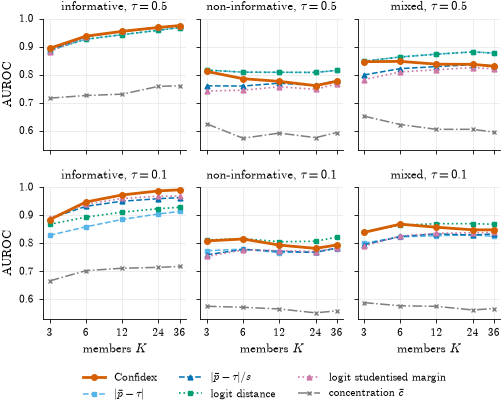

In [12]:
meth = [("confidex", "Confidex", OI["vermillion"], "-", "o", 2.0),
        ("distance", r"$|\bar p-\tau|$", OI["sky"], "--", "s", 1.1),
        ("studentised", r"$|\bar p-\tau|/s$", OI["blue"], "--", "^", 1.1),
        ("logit distance", "logit distance", OI["green"], ":", "s", 1.2),
        ("logit studentised", "logit studentised margin", OI["purple"], ":", "^", 1.2),
        ("concentration", r"concentration $\bar c$", OI["grey"], "-.", "x", 1.1)]
fig, axes = plt.subplots(2, 3, figsize=(TEXTWIDTH, 3.9), sharex=True, sharey=True, gridspec_kw={"hspace": 0.28, "wspace": 0.1})
for j, d in enumerate(DESIGNS):
    for i, tau in enumerate((0.5, 0.1)):
        ax = axes[i, j]
        for key, lab, col, ls, mk, lw in meth:
            ax.plot(KV, [VAL[f"{d}|{tau}|{K}"][key] for K in KV], color=col, ls=ls, marker=mk, lw=lw,
                    ms=4 if key == "confidex" else 3.5, label=lab, zorder=3 if key == "confidex" else 2)
        ax.set_xscale("log", base=2); ax.set_xticks(KV); ax.set_xticklabels([str(k) for k in KV])
        ax.minorticks_off(); ax.set_ylim(0.53, 1.0); ax.set_title(rf"{d}, $\tau={tau}$")
        if i == 1: ax.set_xlabel(r"members $K$")
        if j == 0: ax.set_ylabel("AUROC")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.0))
show(fig, "confidex_validation")

### 4.4 Difference from the best simple reading, with bootstrap intervals (`fig:amplification`)

For each condition, the difference between the AUROC of Confidex and that of the **best of the four simple readings
in that condition** (distance, studentised margin, and the two on the logit scale), with a 95% percentile interval
from 200 bootstrap resamples of the cases. The same resample is used for both scores, so the interval is for the
paired difference. The best reading is selected on the same data on which the difference is measured: the choice
favours the alternative, so the comparison is conservative for Confidex.

The cases are regenerated from the same seeds as in Section 4.2; the bootstrap has its own generator, seeded once
with 2026 and used across the conditions in the fixed order of the loop. The results are cached in
`gap_bootstrap.json`; delete the file to recompute them.

In [13]:
REF_GAP = json.loads(Path("results/auroc_gap_bootstrap.json").read_text())
if RECOMPUTE:
    G, rng_b, t0 = {}, np.random.default_rng(2026), time.time()
    for d in DESIGNS:
        for tau in (0.5, 0.1):
            for K in KV:
                P, q, _ = simulate(d, K, tau, 20000, seed_for(d, tau, K, "val"))
                post = cx.fit_posterior(P, taus=[tau]); o = cx.confidence_score(post, None, tau)
                err = ((post.mu >= tau) != (q >= tau)).astype(int)
                bl = baselines(P, post.mu, tau); best = max(bl, key=lambda k: auroc(bl[k], err))
                sc_c, sc_b = -o["u"], bl[best]
                boots = []
                for _ in range(200):
                    ii = rng_b.integers(0, len(err), len(err))
                    boots.append(auroc(sc_c[ii], err[ii]) - auroc(sc_b[ii], err[ii]))
                G[f"{d}|{tau}|{K}"] = {"gap": auroc(sc_c, err) - auroc(sc_b, err), "lo": float(np.quantile(boots, 0.025)),
                                       "hi": float(np.quantile(boots, 0.975)), "best": best}
    print(f"bootstrap computed ({time.time() - t0:.0f} s)")
    for key, g in G.items():
        for q_ in ("gap", "lo", "hi"):
            check("bootstrap", f"{key} {q_}", g[q_], REF_GAP[key][q_], tol=1e-12)
        check("bootstrap", f"{key} best reading", float(g["best"] == REF_GAP[key]["best"]), 1.0, tol=0)
else:
    G = REF_GAP

for key, g in G.items():                       # the point estimate must agree with the validation table
    check("bootstrap", f"{key} gap against the validation table", g["gap"], VAL[key]["confidex"] - VAL[key][g["best"]], tol=1e-12)
report("bootstrap")

print(f"\n{'design':<16}{'tau':>5}{'K':>4}   gap      95% interval        best simple reading")
for key, g in G.items():
    d, tau, K = key.split("|"); sig = "  " if g["lo"] <= 0 <= g["hi"] else " *"
    print(f"{d:<16}{tau:>5}{K:>4}  {g['gap']:+.4f}  [{g['lo']:+.4f}, {g['hi']:+.4f}]{sig}  {g['best']}")
print("\n* interval excludes zero")


bootstrap computed (226 s)
[bootstrap] 150/150 recomputed values match the reference (largest difference 0.0e+00)

design            tau   K   gap      95% interval        best simple reading
informative       0.5   3  +0.0069  [+0.0056, +0.0083] *  distance
informative       0.5   6  +0.0020  [+0.0008, +0.0034] *  studentised
informative       0.5  12  -0.0003  [-0.0010, +0.0003]    logit studentised
informative       0.5  24  -0.0001  [-0.0003, +0.0000]    studentised
informative       0.5  36  +0.0000  [-0.0001, +0.0001]    studentised
informative       0.1   3  -0.0060  [-0.0114, -0.0004] *  logit studentised
informative       0.1   6  +0.0079  [+0.0057, +0.0098] *  logit studentised
informative       0.1  12  +0.0125  [+0.0105, +0.0141] *  logit studentised
informative       0.1  24  +0.0188  [+0.0168, +0.0211] *  logit studentised
informative       0.1  36  +0.0221  [+0.0202, +0.0247] *  logit studentised
non-informative   0.5   3  -0.0050  [-0.0063, -0.0035] *  distance
non-info

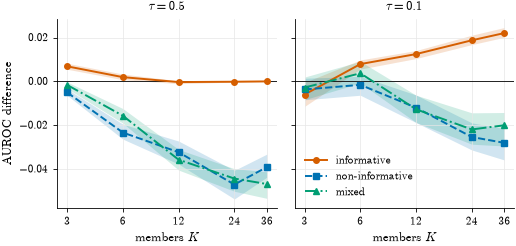

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(TEXTWIDTH, 2.45), sharey=True, gridspec_kw={"wspace": 0.08})
dcol = {"informative": (OI["vermillion"], "o", "-"), "non-informative": (OI["blue"], "s", "--"), "mixed": (OI["green"], "^", "-.")}
for ax, tau in zip(axes, (0.5, 0.1)):
    ax.axhline(0, color="black", lw=0.6)
    for d in DESIGNS:
        col, mk, ls = dcol[d]
        g = [G[f"{d}|{tau}|{K}"] for K in KV]
        ax.fill_between(KV, [x["lo"] for x in g], [x["hi"] for x in g], color=col, alpha=0.18, lw=0)
        ax.plot(KV, [x["gap"] for x in g], color=col, marker=mk, ls=ls, label=d)
    ax.set_xscale("log", base=2); ax.set_xticks(KV); ax.set_xticklabels([str(k) for k in KV]); ax.minorticks_off()
    ax.set_title(rf"$\tau={tau}$"); ax.set_xlabel(r"members $K$")
axes[0].set_ylabel("AUROC difference"); axes[1].legend(loc="lower left")
show(fig, "confidex_amplification")

### 4.5 A fixed review budget (`fig:budget`)

The AUROC integrates over every cut-off, whereas in deployment the cut is set by the capacity of review
(Chapter 2, *Per-sample confidence and referral*). The same thirty conditions are therefore also scored at a fixed
budget: each reading sends to review the $b\%$ of the cases with the most doubt, $b\in\{5,10,20\}$, and the share of
all errors that falls among them is recorded. At a fixed budget the precision of the referrals equals that share times
the number of errors divided by the number of cases referred, so the two orderings agree and only the share is reported.

The difference between Confidex and the best of the four simple readings at $b=10\%$ (the best is chosen at that
budget, in each condition, which favours the alternative) has a 95% paired bootstrap interval, from 200 resamples
drawn with a generator seeded by the condition, `seed_for(design, tau, K, "budget")`, so that each condition is
reproducible on its own. `errors_in_10pct` is the ratio between the number of cases referred and the number of
errors: when it is below one, not even a perfect score could capture all the errors within the budget.

In [15]:
for tau in (0.5, 0.1):
    print(f"\ntau = {tau}: share of errors captured when referring 10% of the cases (percent)")
    print(f"{'design':<16}{'K':>4}  {'Confidex':>8} {'best simple':>12}  {'gap':>6}   95% interval        best reading      10%/errors")
    for d in DESIGNS:
        for K in KV:
            g = BUD[f"{d}|{tau}|{K}"]; best = g["best@0.1"]
            sig = "  " if g["lo@0.1"] <= 0 <= g["hi@0.1"] else " *"
            print(f"{d:<16}{K:>4}  {100*g['confidex@0.1']:8.1f} {100*g[best+'@0.1']:12.1f}  {100*g['gap@0.1']:+6.1f}"
                  f"   [{100*g['lo@0.1']:+5.1f}, {100*g['hi@0.1']:+5.1f}]{sig}  {best:<17} {g['errors_in_10pct']:.2f}")
print("\n* interval excludes zero")
print("\nConfidex minus the best simple reading at each budget, percentage points, K = 3, 6, 12, 24, 36:")
for d in DESIGNS:
    for tau in (0.5, 0.1):
        cells = []
        for b in BUDGETS:
            gaps = [100 * (BUD[f"{d}|{tau}|{K}"][f"confidex@{b}"] - max(BUD[f"{d}|{tau}|{K}"][f"{m}@{b}"] for m in SIMPLE)) for K in KV]
            cells.append(f"{int(100*b)}%: " + " ".join(f"{x:+.1f}" for x in gaps))
        print(f"  {d:<16} tau = {tau}:  " + "  |  ".join(cells))


tau = 0.5: share of errors captured when referring 10% of the cases (percent)
design             K  Confidex  best simple     gap   95% interval        best reading      10%/errors
informative        3      50.5         50.3    +0.2   [ -1.7,  +1.5]    logit studentised 1.38
informative        6      68.0         68.0    +0.0   [ -1.1,  +1.5]    studentised       1.90
informative       12      80.1         80.5    -0.4   [ -1.5,  +1.6]    logit studentised 2.77
informative       24      89.7         90.6    -1.0   [ -1.4,  +0.6]    logit studentised 3.83
informative       36      96.2         96.5    -0.2   [ -1.3,  +0.6]    logit studentised 4.42
non-informative    3      33.9         33.5    +0.4   [ -0.3,  +1.1]    distance          0.81
non-informative    6      32.3         33.2    -0.9   [ -1.9,  +0.1]    distance          0.81
non-informative   12      30.9         32.2    -1.3   [ -2.4,  -0.3] *  distance          0.89
non-informative   24      31.6         32.9    -1.3   [ -2

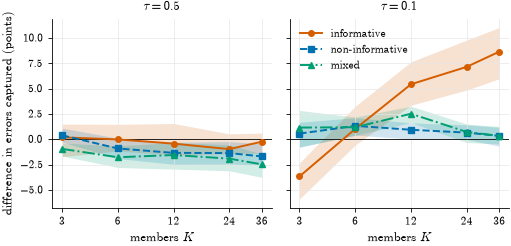

In [16]:
dcol = {"informative": (OI["vermillion"], "o", "-"), "non-informative": (OI["blue"], "s", "--"), "mixed": (OI["green"], "^", "-.")}
fig, axes = plt.subplots(1, 2, figsize=(TEXTWIDTH, 2.45), sharey=True, gridspec_kw={"wspace": 0.08})
for ax, tau in zip(axes, (0.5, 0.1)):
    ax.axhline(0, color="black", lw=0.6)
    for d in DESIGNS:
        col, mk, ls = dcol[d]
        g = [BUD[f"{d}|{tau}|{K}"] for K in KV]
        ax.fill_between(KV, [100 * x["lo@0.1"] for x in g], [100 * x["hi@0.1"] for x in g], color=col, alpha=0.18, lw=0)
        ax.plot(KV, [100 * x["gap@0.1"] for x in g], color=col, marker=mk, ls=ls, label=d)
    ax.set_xscale("log", base=2); ax.set_xticks(KV); ax.set_xticklabels([str(k) for k in KV]); ax.minorticks_off()
    ax.set_title(rf"$\tau={tau}$"); ax.set_xlabel(r"members $K$")
axes[0].set_ylabel("difference in errors captured (points)"); axes[1].legend(loc="upper left")
show(fig, "confidex_budget")

### 4.6 Values quoted in the chapter

The quantities on which the text of `sec:conf-validation` relies. Each line names the statement it supports.

In [17]:
V = VAL
by = lambda pred: [v for k, v in V.items() if pred(*k.split("|"))]
rho3 = [v["rho"] for v in by(lambda d, t, K: K == "3")]; rho12 = [v["rho"] for v in by(lambda d, t, K: K == "12")]
print(f"Recovery of the scale: Spearman rho {min(rho3):.2f}-{max(rho3):.2f} at K = 3, {min(rho12):.2f}-{max(rho12):.2f} at K = 12")
conc = [v["concentration"] for v in V.values()]
others = [max(v[c] for c in cols[:5]) for v in V.values()]
print(f"Concentration read directly: AUROC {min(conc):.3f}-{max(conc):.3f}; poorest reading in "
      f"{sum(v['concentration'] < min(v[c] for c in cols[:5]) for v in V.values())}/30 conditions")
for K in (3, 6, 12):
    r = V[f"informative|0.5|{K}"]; print(f"Informative, tau = 0.5, K = {K:>2}: Confidex {r['confidex']:.3f}, studentised {r['studentised']:.3f}")
for K in (6, 12):
    r = V[f"informative|0.1|{K}"]
    print(f"Informative, tau = 0.1, K = {K:>2}: Confidex {r['confidex']:.3f}, logit studentised {r['logit studentised']:.3f}, "
          f"distance {r['distance']:.3f}, logit distance {r['logit distance']:.3f}")
for d in ("non-informative", "mixed"):
    r = V[f"{d}|0.5|12"]; print(f"{d}, tau = 0.5, K = 12: distance {r['distance']:.3f}, Confidex {r['confidex']:.3f}")
side = {d: (V[f"{d}|0.1|3"]["opposite"], V[f"{d}|0.1|3"]["confidex"] - V[f"{d}|0.1|3"]["band"]) for d in DESIGNS}
print("Side of the decision, tau = 0.1, K = 3: law on the opposite side in "
      f"{100*min(s[0] for s in side.values()):.1f}%-{100*max(s[0] for s in side.values()):.1f}% of cases; "
      f"AUROC lost without the condition {min(s[1] for s in side.values()):.3f}-{max(s[1] for s in side.values()):.3f}")
r = V["informative|0.1|3"]; print(f"   e.g. informative: {r['band']:.3f} without the condition, {r['confidex']:.3f} with it")
print(f"Side of the decision at tau = 0.5: largest share on the opposite side {max(v['opposite'] for k, v in V.items() if '|0.5|' in k):.4f}")
print(f"Law at cbar vs predictive law: same verdict in at least {100*min(v['agree_plugin'] for v in V.values()):.2f}% of cases, "
      f"AUROC within {max(abs(v['confidex'] - v['confidex plug-in']) for v in V.values()):.4f}")
wins = sum(v["rank_recall"] > v["gate_recall"] for v in V.values())
print(f"Gate: ranking by u captures more errors than the gate in {wins}/30 conditions")
for key in ("informative|0.5|12", "mixed|0.1|12"):
    print(f"   {key}: ranking {100*V[key]['rank_recall']:.1f}%, gate {100*V[key]['gate_recall']:.1f}%")
low = [k for k, v in V.items() if "|0.1|" in k and int(k.split("|")[2]) <= 12 and v["gate_err_excluded"] < v["gate_err_admitted_conf"]]
print(f"   at tau = 0.1 and K <= 12, cases set aside are wrong less often than those admitted and declared confident in {len(low)}/9 conditions")
for K in KV:
    g = G[f"informative|0.5|{K}"]; print(f"Informative, tau = 0.5, K = {K:>2}: AUROC gap to the best simple reading {g['gap']:+.4f} [{g['lo']:+.4f}, {g['hi']:+.4f}]")
print("tau = 0.5, K = 3, distance ahead of Confidex by: " + ", ".join(f"{d} {V[f'{d}|0.5|3']['distance'] - V[f'{d}|0.5|3']['confidex']:.4f}" for d in ("non-informative", "mixed")))
for tau in (0.5, 0.1):
    for d in DESIGNS:
        gs = [BUD[f"{d}|{tau}|{K}"] for K in KV]
        print(f"Budget 10%, {d:<15} tau = {tau}: gap " + ", ".join(f"{100*x['gap@0.1']:+.1f}" for x in gs)
              + " points; interval excludes zero at K = " + str([K for K, x in zip(KV, gs) if not (x['lo@0.1'] <= 0 <= x['hi@0.1'])]))

Recovery of the scale: Spearman rho 0.39-0.59 at K = 3, 0.74-0.86 at K = 12
Concentration read directly: AUROC 0.551-0.760; poorest reading in 30/30 conditions
Informative, tau = 0.5, K =  3: Confidex 0.894, studentised 0.885
Informative, tau = 0.5, K =  6: Confidex 0.937, studentised 0.935
Informative, tau = 0.5, K = 12: Confidex 0.954, studentised 0.954
Informative, tau = 0.1, K =  6: Confidex 0.947, logit studentised 0.939, distance 0.858, logit distance 0.893
Informative, tau = 0.1, K = 12: Confidex 0.972, logit studentised 0.959, distance 0.885, logit distance 0.911
non-informative, tau = 0.5, K = 12: distance 0.808, Confidex 0.776
mixed, tau = 0.5, K = 12: distance 0.873, Confidex 0.837
Side of the decision, tau = 0.1, K = 3: law on the opposite side in 2.1%-2.3% of cases; AUROC lost without the condition 0.009-0.022
   e.g. informative: 0.861 without the condition, 0.884 with it
Side of the decision at tau = 0.5: largest share on the opposite side 0.0000
Law at cbar vs predictiv

## 5. Sensitivity to the modelling choices (`sec:conf-sensitivity`)

**Question.** Each modelling choice changes the posterior; the relevant question is whether it changes the
**verdict** of the criterion. Each choice is varied in turn and the share of verdicts that change is recorded, on
2000 cases of the mixed design for each $K\in\{3,6,12,24,36\}$, at $\tau=0.5$ and $\tau=0.25$.

| Choice | Variants | Reference |
|---|---|---|
| prior on $c$ | Beta(2,2), Beta(½,½), Beta(2,3) | uniform Beta(1,1), the canonical reference |
| anchoring $\lambda_0$ | $0.1K$, $K/3$, $3K$, $10K$ | $\lambda_0=K$ |
| law used by the criterion | law at $\bar c$ | predictive law (reported as the share of *identical* verdicts) |
| fixed mean | location inferred, flat prior on $\mu$, grid $160\times160$ | fixed mean $\mu=\bar p$ |

**Fixed against inferred mean.** The specification with independent priors on $(\mu,c)$ is computed on a
two-dimensional grid by `fit_posterior_full`, and the verdict uses its predictive law, which integrates over both
parameters, with the same directional rule and $\alpha=0.40$. The comparison is restricted to the cases whose mean
lies in $(0.05,0.95)$, where that specification is a reliable yardstick (`sec:conf-limits`; near the ends of the
interval its posterior on $\mu$ can move far from $\bar p$), and to the first 1200 of them, for computing time.
`conf_only_fixed` is the share declared confident with the fixed mean and not with the inferred one.

Two further quantities: `border4`, the largest change of $\bar c$ when the grid border moves from $10^{-6}$ to
$10^{-4}$ (mixed design, $K=6$, $\tau=0.5$); and `atten_K`, the median ratio of the posterior precisions $\bar\lambda$
obtained with $\lambda_0=10K$ and $\lambda_0=0.1K$. A hundredfold change in the anchoring that left the data
irrelevant would give a ratio of 100; a ratio close to 1 means that the data override the anchoring.

In [18]:
KS = (3, 6, 12, 24, 36)
if RECOMPUTE:
    SENS, t0 = {"prior": {}, "lambda0": {}, "plugin": {}, "fixed_mean": {}}, time.time()
    for tau in (0.5, 0.25):
        for K in KS:
            P, _, _ = simulate("mixed", K, tau, 2000, seed_for("mixed", tau, K, "sens"))
            def verdict(cfg):
                p = cx.fit_posterior(P, cfg, taus=[tau]); return cx.confidence_score(p, None, tau)["confident"], p
            v_uniform, _ = verdict(ModelConfig(prior_a=1, prior_b=1))
            SENS["prior"][f"{tau}|{K}"] = {name: float(np.mean(verdict(ModelConfig(prior_a=a, prior_b=b))[0] != v_uniform))
                                           for name, (a, b) in {"2,2": (2, 2), "0.5,0.5": (0.5, 0.5), "2,3": (2, 3)}.items()}
            vK, pK = verdict(ModelConfig())
            SENS["lambda0"][f"{tau}|{K}"] = {str(sc): float(np.mean(verdict(ModelConfig(lambda0_scale=sc))[0] != vK))
                                             for sc in (0.1, 1/3, 3, 10)}
            vplug = cx.confidence_score(pK, cx.member_law(pK), tau, predictive=False)["confident"]
            SENS["plugin"][f"{tau}|{K}"] = float(np.mean(vplug == vK))
            keep = (P.mean(1) > 0.05) & (P.mean(1) < 0.95); Pk = P[keep][:1200]
            pf = cx.fit_posterior(Pk, taus=[tau]); vfix = cx.confidence_score(pf, None, tau)["confident"]
            Fp = cx.fit_posterior_full(Pk, points_mu=160, points_c=160, taus=[tau]).F_pred[tau]
            vfull = np.where(Pk.mean(1) >= tau, Fp < 0.4, Fp > 0.6)
            SENS["fixed_mean"][f"{tau}|{K}"] = {"changed": float(np.mean(vfix != vfull)),
                                                "conf_only_fixed": float(np.mean(vfix & ~vfull)),
                                                "conf_only_full": float(np.mean(~vfix & vfull))}
            print(f"tau = {tau}, K = {K:>2} done  ({time.time() - t0:.0f} s)")
    P, _, _ = simulate("mixed", 6, 0.5, 2000, seed_for("mixed", 0.5, 6, "sens"))
    SENS["border4"] = float(np.max(np.abs(cx.fit_posterior(P, ModelConfig(grid_bound=1e-4)).c_mean - cx.fit_posterior(P).c_mean)))
    for K in (3, 12):
        P, _, _ = simulate("mixed", K, 0.5, 2000, seed_for("mixed", 0.5, K, "sens"))
        SENS[f"atten_{K}"] = float(np.median(cx.fit_posterior(P, ModelConfig(lambda0_scale=10)).lam
                                             / cx.fit_posterior(P, ModelConfig(lambda0_scale=0.1)).lam))
    for part in ("prior", "lambda0", "fixed_mean"):
        for key, dct in SENS[part].items():
            for q_, v in dct.items():
                check("sensitivity", f"{part} {key} {q_}", v, REF["sensitivity"][part][key][q_], tol=1e-12)
    for key, v in SENS["plugin"].items():
        check("sensitivity", f"plugin {key}", v, REF["sensitivity"]["plugin"][key], tol=1e-12)
    for k in ("border4", "atten_3", "atten_12"):
        check("sensitivity", k, SENS[k], REF["sensitivity"][k], tol=1e-12)
    report("sensitivity")
else:
    SENS = REF["sensitivity"]

tau = 0.5, K =  3 done  (5 s)


tau = 0.5, K =  6 done  (10 s)


tau = 0.5, K = 12 done  (14 s)


tau = 0.5, K = 24 done  (19 s)


tau = 0.5, K = 36 done  (23 s)


...

tau = 0.25, K =  6 done  (37 s)


tau = 0.25, K = 12 done  (43 s)


tau = 0.25, K = 24 done  (50 s)


tau = 0.25, K = 36 done  (56 s)


[sensitivity] 113/113 recomputed values match the reference (largest difference 0.0e+00)


In [19]:
pct = lambda x: f"{100*x:5.1f}%"
print("Share of verdicts that change\n")
print(f"{'tau':>5} {'K':>3} | prior vs uniform: 2,2   1/2,1/2  2,3 | lambda0 vs K: 0.1K   K/3    3K    10K | fixed vs inferred mean | same verdict, law at cbar")
for tau in ("0.5", "0.25"):
    for K in KS:
        k = f"{tau}|{K}"; p, l, f = SENS["prior"][k], SENS["lambda0"][k], SENS["fixed_mean"][k]
        print(f"{tau:>5} {K:>3} |      {pct(p['2,2'])} {pct(p['0.5,0.5'])} {pct(p['2,3'])}  |     "
              f"{pct(l['0.1'])} {pct(l['0.3333333333333333'])} {pct(l['3'])} {pct(l['10'])} |   {pct(f['changed'])}"
              f" ({pct(f['conf_only_fixed'])} only fixed) |  {pct(SENS['plugin'][k])}")

Share of verdicts that change

  tau   K | prior vs uniform: 2,2   1/2,1/2  2,3 | lambda0 vs K: 0.1K   K/3    3K    10K | fixed vs inferred mean | same verdict, law at cbar
  0.5   3 |        1.1%   0.4%   2.6%  |       7.0%   3.2%   2.1%   3.5% |     6.8% (  6.8% only fixed) |   98.9%
  0.5   6 |        0.3%   0.1%   0.9%  |       2.3%   1.1%   1.2%   1.7% |     1.7% (  1.7% only fixed) |   99.4%
  0.5  12 |        0.1%   0.1%   0.2%  |       0.9%   0.4%   0.5%   0.8% |     0.8% (  0.8% only fixed) |  100.0%
  0.5  24 |        0.2%   0.2%   0.2%  |       0.6%   0.4%   0.1%   0.2% |     0.5% (  0.4% only fixed) |  100.0%
  0.5  36 |        0.1%   0.0%   0.1%  |       0.4%   0.1%   0.0%   0.1% |     0.6% (  0.3% only fixed) |  100.0%
 0.25   3 |        1.0%   0.4%   3.6%  |      11.2%   5.0%   3.0%   4.4% |    15.5% ( 12.0% only fixed) |   99.1%
 0.25   6 |        0.4%   0.2%   1.3%  |       4.2%   1.8%   1.3%   2.1% |     4.5% (  3.8% only fixed) |   99.4%
 0.25  12 |        0.1%   0.1

**Values quoted in the chapter** (`sec:conf-sensitivity`).

In [20]:
pr, l0, fm, pl = SENS["prior"], SENS["lambda0"], SENS["fixed_mean"], SENS["plugin"]
K_of = lambda k: int(k.split("|")[1]); tau_of = lambda k: k.split("|")[0]
print(f"Prior: largest share changed {100*max(max(v.values()) for v in pr.values()):.1f}% everywhere, "
      f"{100*max(max(v.values()) for k, v in pr.items() if K_of(k) >= 6):.1f}% for K >= 6")
print(f"   Beta(2,3) is the variant farthest from the uniform in "
      f"{sum(v['2,3'] >= max(v.values()) for v in pr.values())}/{len(pr)} conditions; "
      f"largest share from K = 12: {100*max(max(v.values()) for k, v in pr.items() if K_of(k) >= 12):.2f}%")
ext = {k: max(v['0.1'], v['10']) for k, v in l0.items()}; kmax = max(ext, key=ext.get)
print(f"Anchoring, extreme values 0.1K and 10K: up to {100*ext[kmax]:.1f}% (tau = {tau_of(kmax)}, K = {K_of(kmax)})")
pl_ = {k: max(v['0.3333333333333333'], v['3']) for k, v in l0.items()}
print(f"Anchoring, plausible range K/3 and 3K: up to {100*max(v for k, v in pl_.items() if K_of(k) == 3):.1f}% at K = 3, "
      f"{100*max(v for k, v in pl_.items() if K_of(k) >= 6):.1f}% for K >= 6")
print(f"Law at cbar: same verdict as the predictive law in at least {100*min(v for k, v in pl.items() if K_of(k) == 3):.2f}% of cases at K = 3, "
      f"{100*min(v for k, v in pl.items() if K_of(k) >= 12):.2f}% from K = 12")
for tau in ("0.5", "0.25"):
    print(f"Fixed mean, tau = {tau}: " + ", ".join(f"K = {K}: {100*fm[f'{tau}|{K}']['changed']:.1f}%" for K in KS))
f = fm["0.25|3"]
print(f"   at K = 3, tau = 0.25: {100*f['conf_only_fixed']:.1f}% confident only under the fixed mean, "
      f"{100*f['conf_only_full']:.1f}% only under the inferred mean")
print("   confident only under the inferred mean, tau = 0.5: " + ", ".join(f"K = {K}: {100*fm[f'0.5|{K}']['conf_only_full']:.2f}%" for K in KS))
print(f"Grid border 1e-6 -> 1e-4: largest change of cbar {SENS['border4']:.1e}")
print(f"Anchoring attenuation, median ratio of precisions for a 100-fold change of lambda0: "
      f"{SENS['atten_3']:.1f} at K = 3, {SENS['atten_12']:.2f} at K = 12")

Prior: largest share changed 3.6% everywhere, 1.3% for K >= 6
   Beta(2,3) is the variant farthest from the uniform in 8/10 conditions; largest share from K = 12: 0.25%
Anchoring, extreme values 0.1K and 10K: up to 11.2% (tau = 0.25, K = 3)
Anchoring, plausible range K/3 and 3K: up to 5.0% at K = 3, 1.8% for K >= 6
Law at cbar: same verdict as the predictive law in at least 98.85% of cases at K = 3, 99.75% from K = 12
Fixed mean, tau = 0.5: K = 3: 6.8%, K = 6: 1.7%, K = 12: 0.8%, K = 24: 0.5%, K = 36: 0.6%
Fixed mean, tau = 0.25: K = 3: 15.5%, K = 6: 4.5%, K = 12: 1.6%, K = 24: 1.6%, K = 36: 0.5%
   at K = 3, tau = 0.25: 12.0% confident only under the fixed mean, 3.5% only under the inferred mean
   confident only under the inferred mean, tau = 0.5: K = 3: 0.00%, K = 6: 0.00%, K = 12: 0.08%, K = 24: 0.08%, K = 36: 0.25%
Grid border 1e-6 -> 1e-4: largest change of cbar 2.7e-06
Anchoring attenuation, median ratio of precisions for a 100-fold change of lambda0: 22.8 at K = 3, 2.06 at K = 

## 6. Numerical examples of the remarks

### 6.1 Five members, inferred location (`sec:conf-specs`, `fig:joint-posterior`, `hyp:fixed-mean`)

**What it shows.** Why the fixed mean is acceptable away from the ends of the interval. For the five probabilities
$(0.65, 0.77, 0.40, 0.83, 0.55)$, mean $\bar p=0.64$, the joint posterior of $(\mu,c)$ is computed with a flat prior on
$\mu$, and its marginal on $\mu$ is compared with the fixed value $\bar p$. The posterior standard deviation of $\mu$ is
also compared with $\sigma_{\mathrm{pred}}/\sqrt K$, the standard error of a mean of $K$ draws from the reconstructed law:
their closeness is the finite-sample counterpart of the asymptotic argument (Bernstein–von Mises) by which the
posterior of the location concentrates on $\bar p$ at rate $1/\sqrt K$.

In [21]:
P5 = np.array([[0.65, 0.77, 0.40, 0.83, 0.55]])
full = cx.fit_posterior_full(P5, points_mu=400, points_c=400)
fx = cx.fit_posterior(P5)
FIVE = {"mu_mean": float(full.mu_mean[0]), "mu_sd": float(full.mu_sd[0]), "ci90": full.mu_ci90[0].tolist(),
        "sigma_pred": float(fx.sigma_pred[0]), "sigma_pred_over_sqrtK": float(fx.sigma_pred[0] / np.sqrt(5))}
for k in ("mu_mean", "mu_sd", "ci90", "sigma_pred", "sigma_pred_over_sqrtK"):
    check("examples", f"five {k}", FIVE[k], REF["five"][k], tol=1e-12)
report("examples")
print(f"\npbar = {P5.mean():.3f}; posterior mean of mu {FIVE['mu_mean']:.3f}, sd {FIVE['mu_sd']:.3f}, "
      f"90% interval [{FIVE['ci90'][0]:.3f}, {FIVE['ci90'][1]:.3f}]")
print(f"sigma_pred = {FIVE['sigma_pred']:.3f};  sigma_pred / sqrt(K) = {FIVE['sigma_pred_over_sqrtK']:.3f}  (compare with sd of mu)")

[examples] 6/6 recomputed values match the reference (largest difference 0.0e+00)



pbar = 0.640; posterior mean of mu 0.620, sd 0.085, 90% interval [0.471, 0.747]
sigma_pred = 0.187;  sigma_pred / sqrt(K) = 0.084  (compare with sd of mu)


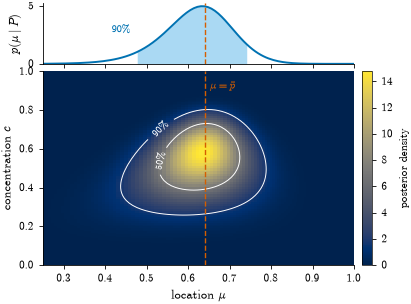

In [22]:
full = cx.fit_posterior_full(P5, points_mu=500, points_c=500, keep_joint=True)   # finer grid, for the figure only
gm, gc = full.grid_mu.g, full.grid_c.g
D = full.joint[0] / (full.grid_mu.w[:, None] * full.grid_c.w[None, :])
mm = full.joint[0].sum(axis=1) / full.grid_mu.w
fig = plt.figure(figsize=(TEXTWIDTH * 0.72, 3.4))
gs = gridspec.GridSpec(2, 2, height_ratios=(1, 3.2), width_ratios=(30, 1), hspace=0.06, wspace=0.05)
axm = fig.add_subplot(gs[0, 0]); axj = fig.add_subplot(gs[1, 0], sharex=axm); cax = fig.add_subplot(gs[1, 1])
lo, hi = FIVE["ci90"]; pbar5 = P5.mean()
axm.plot(gm, mm, color=OI["blue"]); sel = (gm >= lo) & (gm <= hi)
axm.fill_between(gm[sel], 0, mm[sel], color=OI["sky"], alpha=0.5, lw=0)
axm.text(lo - 0.01, 0.55 * mm.max(), f"90{PCT}", ha="right", fontsize=7.5, color=OI["blue"])
axm.axvline(pbar5, color=OI["vermillion"], ls="--", lw=1.0)
axm.set(ylabel=r"$p(\mu\mid P)$", ylim=(0, None)); axm.tick_params(labelbottom=False); axm.grid(False)
pc = axj.pcolormesh(gm, gc, D.T, shading="auto", cmap="cividis", rasterized=True)
M = full.joint[0]; order = np.argsort(M.ravel())[::-1]; cum = np.cumsum(M.ravel()[order])
lev = [D.ravel()[order][np.searchsorted(cum, q_)] for q_ in (0.9, 0.5)]
cs = axj.contour(gm, gc, D.T, levels=lev, colors="white", linewidths=0.7)
axj.clabel(cs, fmt={lev[0]: f"90{PCT}", lev[1]: f"50{PCT}"}, fontsize=7, inline=True)
axj.axvline(pbar5, color=OI["vermillion"], ls="--", lw=1.0)
axj.text(pbar5 + 0.012, 0.95, r"$\mu=\bar p$", color=OI["vermillion"], fontsize=8, va="top")
axj.set(xlim=(0.25, 1.0), ylim=(0, 1), xlabel=r"location $\mu$", ylabel=r"concentration $c$"); axj.grid(False)
cb_ = fig.colorbar(pc, cax=cax); cb_.set_label("posterior density", fontsize=8); cax.grid(False); cb_.outline.set_linewidth(0.5)
show(fig, "confidex_joint_posterior")

*The contours enclose the 50% and 90% highest-posterior regions.*

### 6.2 Shrinkage and the dimensional cancellation (`rem:dimensional`)

By `prop:cancel`, $\sigma_{\mathrm{pred}}=s$ only if the posterior of the relative dispersion concentrated on the moment
estimate. It does not: the likelihood depends on the dispersion on the logarithmic scale, and the prior shrinks it.
The median ratio $\sigma_{\mathrm{pred}}/s$ is computed on 2000 cases of the mixed design at $\tau=0.5$, among the cases
whose reconstructed law is unimodal, for $K\in\{3,6,12,24,36\}$.

### 6.3 The concentration is a relative measure (`sec:conf-relative`), and the moments fail (`rem:mom`)

* Three ensembles of 27 members are built from the quantiles of Beta laws with mean $0.50$, $0.15$ and $0.05$ and the
  same standard deviation $0.044$: same absolute dispersion, different concentration.
* Two polarised ensembles of 27 members: 25 at $0.999$ and 2 at $0.001$; 13 at $0.9$ and 14 at $0.1$. For the first,
  the moment estimate $\hat\lambda_{\mathrm{MoM}}=\bar p(1-\bar p)/s^2-1$ is negative, so that no Beta law exists, while the
  posterior is unaffected.

### 6.4 Anchoring near the ends of the interval (`sec:conf-limits`)

2000 ensembles of three members agreeing within about 20% on probabilities near $0.012$
($\log p_k\sim\mathcal N(\log 0.012,\,0.2^2)$): the share whose reconstructed law is J- or U-shaped, and the median
$\sigma_{\mathrm{pred}}/s$.

### 6.5 Sign of the correlation used by the gate (`rem:gate`)

Spearman correlation between $\mathrm{Var}(c\mid\mathbf P)$ and $\lvert\bar c-\tfrac12\rvert$, on 5000 cases of the mixed design for
$K\in\{3,6,12,24,36\}$. A change of sign with $K$ means that the posterior variance does not rank the cases consistently
across ensemble sizes, which is one reason why the gate is not part of the procedure.

In [23]:
if RECOMPUTE:
    SHR = {}
    for K in KV:
        P, _, _ = simulate("mixed", K, 0.5, 2000, seed_for("mixed", 0.5, K, "shr"))
        p = cx.fit_posterior(P); uni = cx.shape_regime(cx.member_law(p)) == "unimodal"
        SHR[str(K)] = float(np.median((p.sigma_pred / P.std(axis=1, ddof=1))[uni]))
    EX = {}
    K = 27; qs = (np.arange(K) + 0.5) / K
    for mu_ in (0.50, 0.15, 0.05):
        lam_ = mu_ * (1 - mu_) / 0.044 ** 2 - 1; x_ = B.ppf(qs, mu_ * lam_, (1 - mu_) * lam_)
        EX[f"beta_{mu_}"] = {"s": float(x_.std(ddof=1)), "cbar": float(cx.fit_posterior(x_[None, :]).c_mean[0])}
    for name, x_ in (("25-2", np.r_[np.full(25, 0.999), np.full(2, 0.001)]), ("13-14", np.r_[np.full(13, 0.9), np.full(14, 0.1)])):
        p = cx.fit_posterior(x_[None, :]); s_ = x_.std(ddof=1)
        EX[name] = {"pbar": float(x_.mean()), "cbar": float(p.c_mean[0]), "sigma_pred_over_s": float(p.sigma_pred[0] / s_),
                    "lambda_mom": float(x_.mean() * (1 - x_.mean()) / s_ ** 2 - 1)}
    rng = np.random.default_rng(3); X = np.exp(np.log(0.012) + 0.2 * rng.standard_normal((2000, 3)))
    p = cx.fit_posterior(X)
    ANCH = {"J_or_U": float(np.mean(cx.shape_regime(cx.member_law(p)) != "unimodal")),
            "sigma_pred_over_s": float(np.median(p.sigma_pred / X.std(axis=1, ddof=1)))}
    GATE = {}
    for K in KV:
        P, _, _ = simulate("mixed", K, 0.5, 5000, seed_for("mixed", 0.5, K, "gatecorr"))
        p = cx.fit_posterior(P); GATE[str(K)] = float(spearmanr(p.c_var, np.abs(p.c_mean - 0.5)).correlation)
    for k, v in SHR.items(): check("examples", f"shrinkage K={k}", v, REF["shrinkage"][k], tol=1e-12)
    for name, dct in EX.items():
        for q_, v in dct.items(): check("examples", f"{name} {q_}", v, REF["examples"][name][q_], tol=1e-12)
    for q_, v in ANCH.items(): check("examples", f"anchoring {q_}", v, REF["anchoring_location"][q_], tol=1e-12)
    for k, v in GATE.items(): check("examples", f"gate corr K={k}", v, REF["gate_corr"][k], tol=1e-12)
    report("examples")
else:
    SHR, EX, ANCH, GATE = REF["shrinkage"], REF["examples"], REF["anchoring_location"], REF["gate_corr"]

print("\nShrinkage, median sigma_pred / s (unimodal laws):", ", ".join(f"K = {k}: {v:.2f}" for k, v in SHR.items()))
print("Same dispersion, different location (K = 27):")
for mu_ in (0.50, 0.15, 0.05):
    e = EX[f"beta_{mu_}"]; print(f"   mean {mu_:.2f}: s = {e['s']:.4f}, cbar = {e['cbar']:.3f}")
for name in ("25-2", "13-14"):
    e = EX[name]; print(f"Polarised {name}: pbar = {e['pbar']:.3f}, cbar = {e['cbar']:.3f}, "
                        f"sigma_pred / s = {e['sigma_pred_over_s']:.2f}, lambda_MoM = {e['lambda_mom']:.3f}")
print(f"Three members near 0.012: J- or U-shaped law in {100*ANCH['J_or_U']:.0f}% of cases, median sigma_pred / s = {ANCH['sigma_pred_over_s']:.1f}")
print("Gate correlation Spearman(Var(c|P), |cbar - 1/2|):", ", ".join(f"K = {k}: {v:+.2f}" for k, v in GATE.items()))

[examples] 32/32 recomputed values match the reference (largest difference 0.0e+00)

Shrinkage, median sigma_pred / s (unimodal laws): K = 3: 2.30, K = 6: 1.40, K = 12: 1.10, K = 24: 1.00, K = 36: 0.99
Same dispersion, different location (K = 27):
   mean 0.50: s = 0.0438, cbar = 0.799
   mean 0.15: s = 0.0438, cbar = 0.683
   mean 0.05: s = 0.0429, cbar = 0.467
Polarised 25-2: pbar = 0.925, cbar = 0.046, sigma_pred / s = 0.66, lambda_MoM = -0.023
Polarised 13-14: pbar = 0.485, cbar = 0.050, sigma_pred / s = 0.80, lambda_MoM = 0.505
Three members near 0.012: J- or U-shaped law in 100% of cases, median sigma_pred / s = 14.6
Gate correlation Spearman(Var(c|P), |cbar - 1/2|): K = 3: +0.41, K = 6: -0.52, K = 12: -0.84, K = 24: -0.96, K = 36: -0.98


### 6.6 The grid, exact ties and the Jeffreys prior (`sec:conf-inference`, `prop:ties`)

* **Grid against quadrature, and resolution.** On 120 ensembles drawn from the model itself (40 for each of
  $K=3,6,12$, with random location and $c\sim\mathrm{Beta}(2,3)$), the posterior mean of $c$ from the grid is compared with
  adaptive quadrature, and with the grid recomputed with 500, 2000 and 4000 points instead of 1000.
* **Exact ties.** By `prop:ties` the posterior under an exact tie is proper if and only if $b_0>K/2$. With the prior
  adopted, $b_0=3$, it is proper at $K=3$ and improper from $K=6$. For $K\in\{3,12,36\}$ members all equal to $0.3$, the
  posterior mean of $c$ is computed under four priors and with the grid border moved from $10^{-6}$ to $10^{-9}$: where the
  posterior is improper, the value follows the border of the grid and not the prior.
* **Near-ties.** The same members spread uniformly over $0.3\pm0.002$: mass at the border, change of $\bar c$ when the
  border moves, and spread of $\bar c$ across the four priors.
* **Jeffreys prior.** For one member of the fixed-mean model the Fisher information on the precision is
  $I(\lambda)=\mu^2\psi_1(\mu\lambda)+(1-\mu)^2\psi_1((1-\mu)\lambda)-\psi_1(\lambda)$, with $\psi_1$ the trigamma function, and
  $I(c)=I(\lambda)\,(\mathrm d\lambda/\mathrm dc)^2$. Writing $\pi_J(c)\propto I(c)^{1/2}=h(c)/[c(1-c)]$, the factor $h$ is computed on a
  logit grid of $c$, for $\mu\in\{0.01,0.05,0.15,0.5,0.85,0.99\}$ and $\lambda_0\in\{3,12,36\}$. Analytically, $h\to1$ as $c\to0$, since
  $\psi_1(x)\sim1/x^2$, and $h\to1/\sqrt2$ as $c\to1$, since $\psi_1(x)\sim1/x+1/(2x^2)$.

In [24]:
from scipy.special import polygamma
if RECOMPUTE:
    QD = {"n": 0, "max_vs_quadrature": 0.0, "grid": {}}
    for K in (3, 6, 12):
        X = synthetic_beta_rng(40, K, seed_for("quadrature", K))
        p = cx.fit_posterior(X); QD["n"] += len(X)
        QD["max_vs_quadrature"] = max(QD["max_vs_quadrature"], float(max(abs(p.c_mean[i] - quad_posterior_mean(X[i])) for i in range(len(X)))))
        for J in (500, 2000, 4000):
            dJ = float(np.max(np.abs(cx.fit_posterior(X, ModelConfig(grid_points=J)).c_mean - p.c_mean)))
            QD["grid"][str(J)] = max(QD["grid"].get(str(J), 0.0), dJ)
    TIES = {}
    PRIORS = {"2,3": (2, 3), "1,1": (1, 1), "2,2": (2, 2), "0.5,0.5": (0.5, 0.5)}
    for K in (3, 12, 36):
        tie = np.full((1, K), 0.3); near = (0.3 + 0.002 * np.linspace(-1, 1, K))[None, :]
        t = {f"tie_cbar_{n}": float(cx.fit_posterior(tie, ModelConfig(prior_a=a, prior_b=b)).c_mean[0]) for n, (a, b) in PRIORS.items()}
        t["tie_cbar_bound1e-9"] = float(cx.fit_posterior(tie, ModelConfig(grid_bound=1e-9, grid_points=1500)).c_mean[0])
        p6 = cx.fit_posterior(near); p9 = cx.fit_posterior(near, ModelConfig(grid_bound=1e-9, grid_points=1500))
        prs = [cx.fit_posterior(near, ModelConfig(prior_a=a, prior_b=b)).c_mean[0] for a, b in PRIORS.values()]
        t.update({"near_border_mass": float(p6.border_mass[0]), "near_change_with_bound": float(abs(p6.c_mean[0] - p9.c_mean[0])),
                  "near_cbar": float(p6.c_mean[0]), "near_prior_spread": float(max(prs) - min(prs))})
        TIES[str(K)] = t
    c_ = 1 / (1 + np.exp(-np.linspace(-12, 12, 4001))); hs = []
    for mu_ in (0.01, 0.05, 0.15, 0.5, 0.85, 0.99):
        for lam0 in (3, 12, 36):
            lam_ = lam0 * c_ / (1 - c_)
            I_lam = mu_**2 * polygamma(1, mu_ * lam_) + (1 - mu_)**2 * polygamma(1, (1 - mu_) * lam_) - polygamma(1, lam_)
            hs.append(np.sqrt(I_lam) * (lam0 / (1 - c_)**2) * c_ * (1 - c_))
    hs = np.array(hs)
    JEF = {"h_min": float(hs.min()), "h_max": float(hs.max()), "h_at_c_small": float(hs[:, 0].mean()), "h_at_c_large": float(hs[:, -1].mean())}
    for k in ("n", "max_vs_quadrature"): check("grid", f"quadrature {k}", QD[k], REF["quadrature"][k], tol=1e-12)
    for J, v in QD["grid"].items(): check("grid", f"resolution J={J}", v, REF["quadrature"]["grid"][J], tol=1e-12)
    for K, dct in TIES.items():
        for q_, v in dct.items(): check("grid", f"ties K={K} {q_}", v, REF["ties"][K][q_], tol=1e-12)
    for q_, v in JEF.items(): check("grid", f"jeffreys {q_}", v, REF["jeffreys"][q_], tol=1e-12)
    report("grid")
else:
    QD, TIES, JEF = REF["quadrature"], REF["ties"], REF["jeffreys"]

print(f"\nGrid vs adaptive quadrature over {QD['n']} ensembles: largest |difference| in E[c | P] {QD['max_vs_quadrature']:.1e}")
print("Grid resolution (vs 1000 points): " + ", ".join(f"{J} points: {v:.1e}" for J, v in QD["grid"].items()))
for K, t in TIES.items():
    pri = ", ".join(f"{n}: {t['tie_cbar_' + n]:.6f}" for n in ("2,3", "1,1", "2,2", "0.5,0.5"))
    print(f"K = {K:>2}, exact tie: cbar by prior {pri}; with border 1e-9: {t['tie_cbar_bound1e-9']:.9f}")
    print(f"        near-tie +-0.002: border mass {t['near_border_mass']:.1e}, change with border {t['near_change_with_bound']:.1e}, "
          f"spread across priors {t['near_prior_spread']:.1e}")
print(f"Jeffreys factor h(c): between {JEF['h_min']:.4f} and {JEF['h_max']:.4f}; mean {JEF['h_at_c_small']:.4f} at the lowest c, "
      f"{JEF['h_at_c_large']:.4f} at the highest (1/sqrt 2 = {2**-0.5:.4f})")

[grid] 36/36 recomputed values match the reference (largest difference 0.0e+00)

Grid vs adaptive quadrature over 120 ensembles: largest |difference| in E[c | P] 7.1e-06
Grid resolution (vs 1000 points): 500 points: 2.1e-05, 2000 points: 5.4e-06, 4000 points: 6.7e-06
K =  3, exact tie: cbar by prior 2,3: 0.727789, 1,1: 0.999458, 2,2: 0.887205, 0.5,0.5: 0.999987; with border 1e-9: 0.727789274
        near-tie +-0.002: border mass 2.0e-24, change with border 5.2e-09, spread across priors 2.7e-01
K = 12, exact tie: cbar by prior 2,3: 0.999999, 1,1: 0.999999, 2,2: 0.999999, 0.5,0.5: 0.999999; with border 1e-9: 0.999999999
        near-tie +-0.002: border mass 1.7e-85, change with border 6.5e-14, spread across priors 1.5e-04
K = 36, exact tie: cbar by prior 2,3: 0.999999, 1,1: 0.999999, 2,2: 0.999999, 0.5,0.5: 0.999999; with border 1e-9: 0.999999999
        near-tie +-0.002: border mass 1.3e-237, change with border 4.8e-14, spread across priors 4.7e-05
Jeffreys factor h(c): between 0.7071 a

### 6.7 Cost of the two laws (`eq:conf-law`)

The approximation at $\bar c$ needs one Beta distribution function per case, the predictive law one per case and per
grid point. The ratio of the two computing times is measured on 20 000 cases; it depends on the machine and is
reported for information, not checked against the reference.

In [25]:
for K in (3, 12, 36):
    P, _, _ = simulate("mixed", K, 0.1, 20000, np.random.default_rng(0))
    t = time.perf_counter(); p = cx.fit_posterior(P); cx.confidence_score(p, cx.member_law(p), 0.1, predictive=False); a = time.perf_counter() - t
    t = time.perf_counter(); p = cx.fit_posterior(P, taus=[0.1]); cx.confidence_score(p, None, 0.1); b = time.perf_counter() - t
    print(f"K = {K:>2}: law at cbar {a:.2f} s, predictive law {b:.2f} s, ratio {a / b:.2f}")

K =  3: law at cbar 1.32 s, predictive law 9.08 s, ratio 0.15


K = 12: law at cbar 1.12 s, predictive law 8.46 s, ratio 0.13


K = 36: law at cbar 0.92 s, predictive law 8.36 s, ratio 0.11


## 7. Reproduction report

Every recomputed value, compared with `results/chapter3_results.json` and `results/auroc_gap_bootstrap.json`. Arrays are compared element by element. The tolerance is $10^{-12}$ in absolute value (exact
equality for verdicts), that is, agreement to numerical precision rather than to the digits printed in the thesis.
With `RECOMPUTE = False` only the internal consistency checks of the bootstrap are run.

In [26]:
sections = []
for c in CHECKS:
    if c[0] not in sections: sections.append(c[0])
total = ok = 0
print(f"{'section':<14}{'values':>8}{'match':>8}{'largest difference':>22}")
for s in sections:
    rows = [c for c in CHECKS if c[0] == s]; n_ok = sum(c[3] for c in rows)
    total += len(rows); ok += n_ok
    print(f"{s:<14}{len(rows):>8}{n_ok:>8}{max(c[2] for c in rows):>22.1e}")
print(f"{'all':<14}{total:>8}{ok:>8}")
print("\nRESULT:", "all recomputed values match the reference." if ok == total else
      f"{total - ok} values differ from the reference; see the MISMATCH lines above.")
print("Figures written to", FIGDIR.resolve() if SAVE_FIGURES else "(not saved)")

section         values   match    largest difference
illustration        90      90               0.0e+00
validation         480     480               0.0e+00
budget             690     690               0.0e+00
bootstrap          150     150               0.0e+00
sensitivity        113     113               0.0e+00
examples            32      32               0.0e+00
grid                36      36               0.0e+00
all               1591    1591

RESULT: all recomputed values match the reference.
Figures written to (not saved)


### Scope of the reproduction

* The notebook reproduces **Chapter 3**. The application to fraud detection of Chapter 4 uses the same library at the
  same version and is documented separately.
* The synthetic designs are fixed in advance and identical across conditions; they were not tuned on the results.
  They establish what the signal *can* detect when the truth is known, not what it detects in a given application.
* In Section 4 the error is defined against an oracle who knows $q$. With real data only the labels are available,
  and they include the aleatoric variability of the outcome, so the AUROC values of this chapter are not comparable
  one to one with those of Chapter 4.